# Proyecto Titanic

## Integrantes

- Alfredo Avila Escobar
- Edson Daniel López López 
- Diego García Cuanalo
- Víctor Antonio Hernández Paredes.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

np.random.seed(42)

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "titanic.csv")
df_original = df.copy()

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


# 1. Primer contacto

- ¿Clasificación o regresión? **R=** Clasificación ya que estamos intentado predecir si un pasajero sobrevivio o murio.

- ¿Qué numérica se comporta como categórica, y qué categórica tiene orden? 
    **R=** Survided, pclass se comportan como categoricas pero son numericas y Class es una numérica que se comporta como categprica

- ¿Qué parejas de columnas dicen lo mismo? Compruébalo.
    **R=** Survided y Alived; pclass y class; embarked y embark_town ya que nos aportan la misma info.

- ¿Qué pasa si le das alive al modelo?
    **R=** Le estamos dando la respuesta al modelo generando Target Leakage (un tipo de Data Leakage). Esto provoca un rendimiento engañosamente perfecto (100% de precisión) durante el entrenamiento, pero hace que el modelo sea completamente inútil en producción porque esa variable no estará disponible al momento de predecir casos nuevos.

### Primeras y últimas filas, número de filas y columnas, tipos de dato

In [3]:
display(df.head())
display(df.tail())
print("Filas y columnas:", df.shape)
df.info()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Filas y columnas: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


### Resumen estadístico de numéricas y categóricas

In [4]:
display(df.describe())
display(df.describe(exclude="number"))

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


### Faltantes por columna: número y porcentaje

In [5]:
faltantes = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
})
faltantes

,nulos,porcentaje
survived,0,0.00
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
class,0,0.00
who,0,0.00


### Filas duplicadas

In [6]:
print("Repeticiones adicionales:", df.duplicated().sum())
print("Filas en grupos idénticos:", df.duplicated(keep=False).sum())
display(df[df.duplicated(keep=False)].head())

Repeticiones adicionales: 107
Filas en grupos idénticos: 160


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True


### Valores únicos de cada categoría

In [7]:
columnas_categoricas = df.select_dtypes(exclude="number").columns

for col in columnas_categoricas:
    print(f"--- Columna: {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

print("Valores de survived:", df["survived"].unique())
print("Valores de pclass:", df["pclass"].unique())

--- Columna: sex ---
sex
male      577
female    314
Name: count, dtype: int64 

--- Columna: embarked ---
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64 

--- Columna: class ---
class
Third     491
First     216
Second    184
Name: count, dtype: int64 

--- Columna: who ---
who
man      537
woman    271
child     83
Name: count, dtype: int64 

--- Columna: adult_male ---
adult_male
True     537
False    354
Name: count, dtype: int64 

--- Columna: deck ---
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64 

--- Columna: embark_town ---
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64 

--- Columna: alive ---
alive
no     549
yes    342
Name: count, dtype: int64 

--- Columna: alone ---
alone
True     537
False    354
Name: count, dtype: int64 

Valores de survived: [0 1]
Valores de pclass: [3 1 2]


### ¿Qué parejas de columnas dicen lo mismo? ¿Hay columnas derivadas de otras?

In [8]:
display(pd.crosstab(df["survived"], df["alive"]))
display(pd.crosstab(df["pclass"], df["class"]))
display(pd.crosstab(df["embarked"], df["embark_town"], dropna=False))

who_calculado = np.where(df["age"] < 16, "child", df["sex"].map({"male": "man", "female": "woman"}))
adult_male_calculado = who_calculado == "man"
alone_calculado = (df["sibsp"] + df["parch"]) == 0

print("who coincide:", (df["who"] == who_calculado).all())
print("adult_male coincide:", (df["adult_male"] == adult_male_calculado).all())
print("alone coincide:", (df["alone"] == alone_calculado).all())

alive,no,yes
survived,,
0,549,0
1,0,342


class,First,Second,Third
pclass,,,
1,216,0,0
2,0,184,0
3,0,0,491


embark_town,Cherbourg,Queenstown,Southampton,NaN
embarked,,,,
C,168,0,0,0
Q,0,77,0,0
S,0,0,644,0
NaN,0,0,0,2


who coincide: True
adult_male coincide: True
alone coincide: True


# 2. Análisis exploratorio

- Si solo pudieras usar una columna para predecir, ¿cuál?
    **R=** Elegiríamos sex, porque en estos datos hay una diferencia grande de supervivencia entre mujeres y hombres. Todavía no entrenamos un modelo para comprobar qué columna predice mejor.

- Tres hallazgos que te sorprendieron.
    **R=** Sobrevivió menos de la mitad de los pasajeros; la supervivencia fue mucho mayor en mujeres que en hombres; y en primera clase sobrevivió un porcentaje mayor que en tercera.

- ¿Algo huele a error en los datos?
    **R=** Hay filas repetidas, faltan muchas edades y datos de deck, y hay tarifas de cero o muy altas. Hay que revisarlos antes de decidir si son errores.

### Porcentaje de supervivientes: ¿las clases están equilibradas?

survived
0    61.62
1    38.38
Name: proportion, dtype: float64

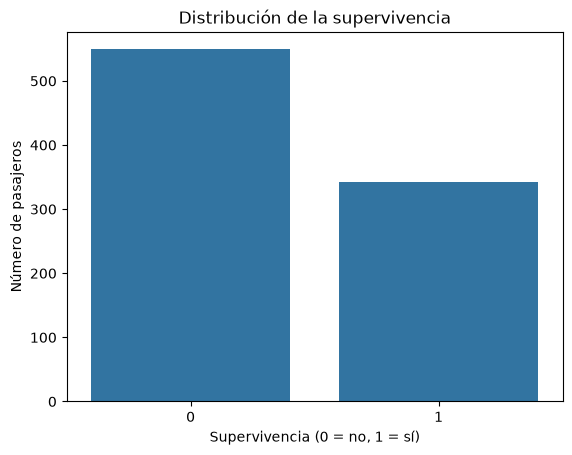

In [10]:
display((df["survived"].value_counts(normalize=True) * 100).round(2))

fig, ax = plt.subplots()
sns.countplot(data=df, x="survived", ax=ax)
ax.set_title("Distribución de la supervivencia")
ax.set_xlabel("Supervivencia (0 = no, 1 = sí)")
ax.set_ylabel("Número de pasajeros")
plt.show()

Supervivencia por sexo y clase

Calculamos el porcentaje que sobrevivió dentro de cada grupo. Como survived vale 0 o 1, su media multiplicada por 100 nos da ese porcentaje.

### Histogramas y boxplots de `age` y `fare`: ¿cómo se distribuyen? ¿Hay valores extremos?

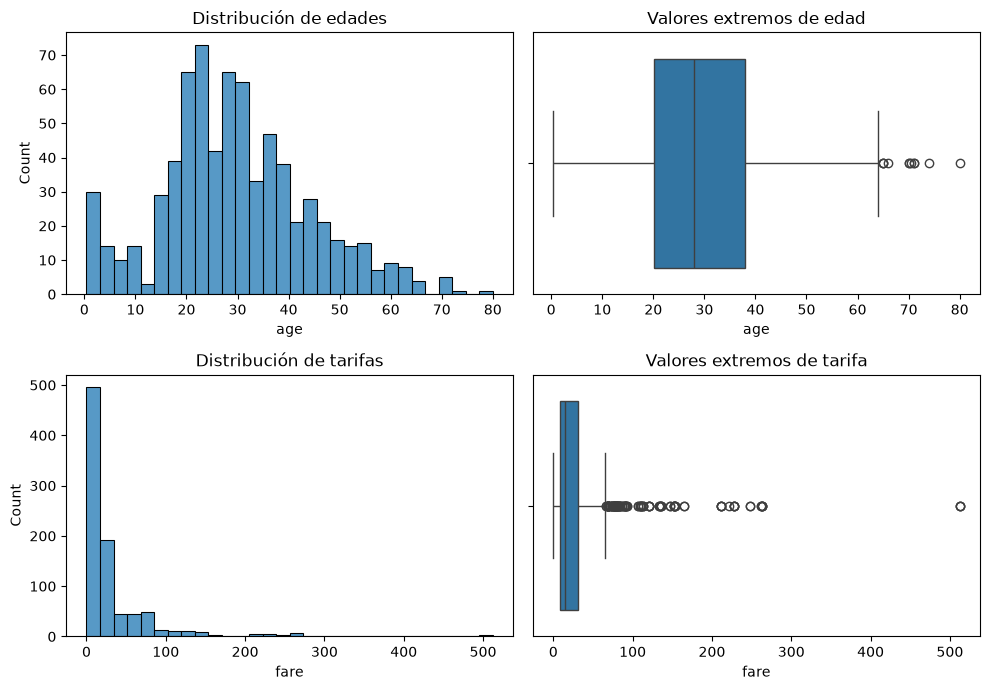

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

sns.histplot(data=df, x="age", bins=30, ax=axes[0, 0])
sns.boxplot(data=df, x="age", ax=axes[0, 1])
sns.histplot(data=df, x="fare", bins=30, ax=axes[1, 0])
sns.boxplot(data=df, x="fare", ax=axes[1, 1])

axes[0, 0].set_title("Distribución de edades")
axes[0, 1].set_title("Valores extremos de edad")
axes[1, 0].set_title("Distribución de tarifas")
axes[1, 1].set_title("Valores extremos de tarifa")

plt.tight_layout()
plt.show()

En age se concentran más pasajeros en edades adultas jóvenes. La mediana es de 28 años y también hay bebés y personas mayores. Estas gráficas no incluyen las 177 edades faltantes.

En fare la mayoría de las tarifas es baja y hay unas pocas mucho más altas. Por eso la media es 32.20, mientras que la mediana es 14.45.

Barras de sexo, clase, puerto y familiares

### Barras de `sex`, `pclass`, `embarked`, `sibsp` y `parch`: ¿qué categorías predominan?

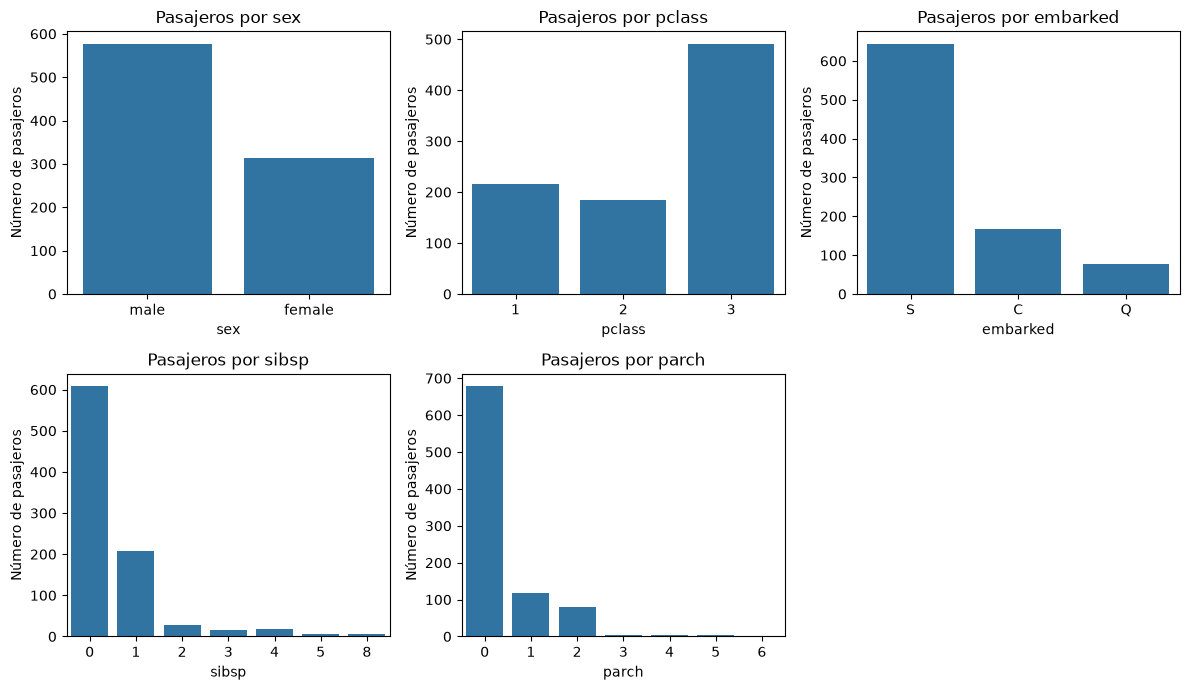

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, col in zip(axes.flat, ["sex", "pclass", "embarked", "sibsp", "parch"]):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Pasajeros por {col}")
    ax.set_ylabel("Número de pasajeros")

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

En `age` se concentran más pasajeros en edades adultas jóvenes. La mediana es de 28 años y también hay bebés y personas mayores. Estas gráficas no incluyen las 177 edades faltantes.

En `fare` la mayoría de las tarifas es baja y hay unas pocas mucho más altas.


### Supervivencia por sexo, clase y `alone`: ¿qué diferencias hay?

,count,mean
sex,,
female,314,74.20
male,577,18.89


,count,mean
pclass,,
1,216,62.96
2,184,47.28
3,491,24.24


,count,mean
alone,,
False,354,50.56
True,537,30.35


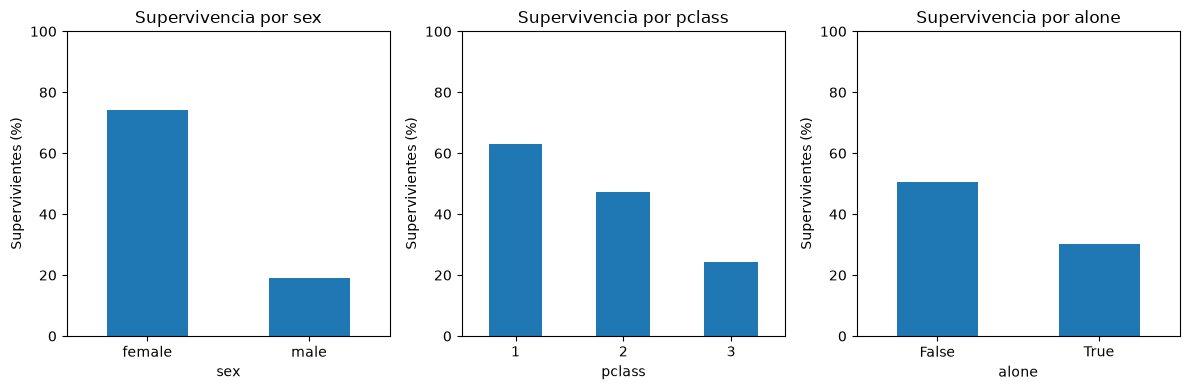

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, ["sex", "pclass", "alone"]):
    resumen = df.groupby(col)["survived"].agg(["count", "mean"])
    resumen["mean"] = resumen["mean"] * 100
    display(resumen.round(2))
    resumen["mean"].plot.bar(ax=ax, rot=0)
    ax.set_title(f"Supervivencia por {col}")
    ax.set_ylabel("Supervivientes (%)")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

- Por sexo, sobrevivió el 74.20% de las mujeres y el 18.89% de los hombres.
- Por clase, sobrevivió el 62.96% de primera, 47.28% de segunda y 24.24% de tercera.
- Entre quienes viajaban solos sobrevivió el 30.35%, y entre quienes tenían familiares registrados, el 50.56%.

Estos porcentajes muestran diferencias entre los grupos, pero no bastan para asegurar qué causó esas diferencias.

### Supervivencia por edad y tarifa: ¿qué muestran los tramos?

,count,mean
age_group,,
infancia,69,57.97
adolescencia,44,47.73
adultez,575,38.61
mayor,26,26.92


,count,mean
fare_group,,
"(-0.001, 7.91]",223,19.73
"(7.91, 14.454]",224,30.36
"(14.454, 31.0]",222,45.50
"(31.0, 512.329]",222,58.11


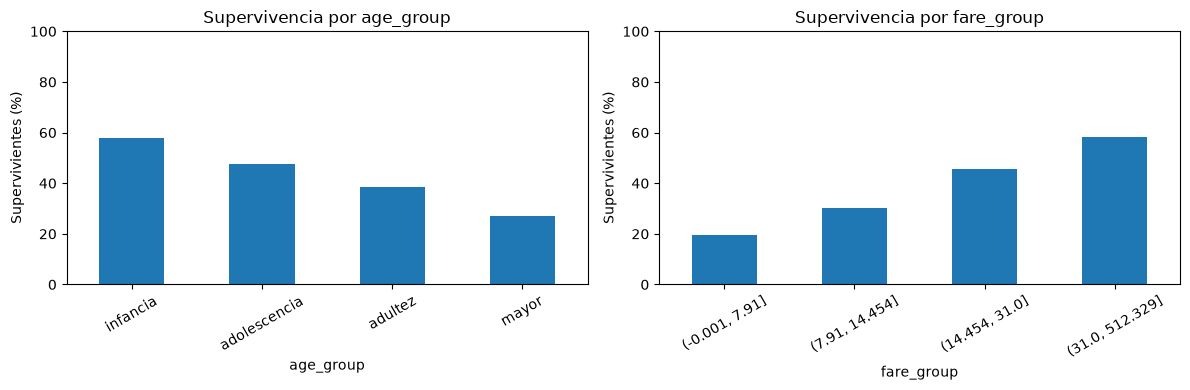

In [14]:
eda = df.copy()
eda["age_group"] = pd.cut(eda["age"], bins=[0, 12, 17, 59, np.inf],
                          labels=["infancia", "adolescencia", "adultez", "mayor"], include_lowest=True)
eda["fare_group"] = pd.qcut(eda["fare"], q=4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ["age_group", "fare_group"]):
    resumen = eda.groupby(col, observed=True)["survived"].agg(["count", "mean"])
    resumen["mean"] = resumen["mean"] * 100
    display(resumen.round(2))
    resumen["mean"].plot.bar(ax=ax, rot=30)
    ax.set_title(f"Supervivencia por {col}")
    ax.set_ylabel("Supervivientes (%)")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

En edad, el porcentaje de supervivencia es mayor en el grupo de hasta 12 años y menor en el de más de 59. Hay que tener en cuenta que faltan edades y que los grupos no tienen la misma cantidad de personas.

En tarifa, los grupos más caros tienen mayor supervivencia que el grupo de hasta 10 libras. El precio también está relacionado con la clase del pasajero.

### ¿Influyó el puerto? Antes de concluir, cruza puerto con clase

embarked
C    55.36
Q    38.96
S    33.70
Name: survived, dtype: float64

pclass,1,2,3
embarked,,,
C,50.60,10.12,39.29
Q,2.60,3.90,93.51
S,19.72,25.47,54.81


pclass,1,2,3
embarked,,,
C,69.41,52.94,37.88
Q,50.00,66.67,37.50
S,58.27,46.34,18.98


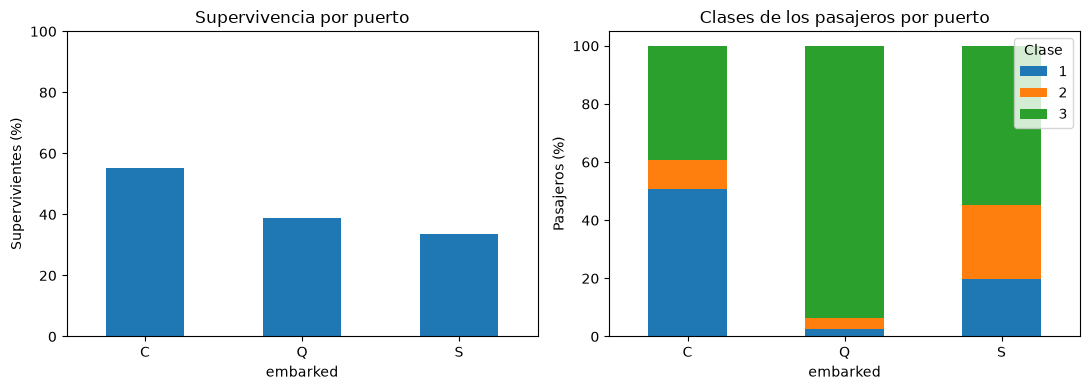

In [15]:
supervivencia_puerto = df.groupby("embarked")["survived"].mean() * 100
puerto_clase = pd.crosstab(df["embarked"], df["pclass"], normalize="index") * 100

display(supervivencia_puerto.round(2))
display(puerto_clase.round(2))
display((df.groupby(["embarked", "pclass"])["survived"].mean() * 100).unstack().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
supervivencia_puerto.plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Supervivencia por puerto")
axes[0].set_ylabel("Supervivientes (%)")
axes[0].set_ylim(0, 100)
puerto_clase.plot.bar(stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Clases de los pasajeros por puerto")
axes[1].set_ylabel("Pasajeros (%)")
axes[1].legend(title="Clase")

plt.tight_layout()
plt.show()

En Cherbourg (C) sobrevivió el 55.36%, en Queenstown (Q) el 38.96% y en Southampton (S) el 33.70%. Revisamos también qué clases viajaban desde cada puerto.

### Mujeres de tercera clase frente a hombres de primera: ¿quiénes tuvieron mayor supervivencia?

,pasajeros,supervivencia (%)
Mujeres de tercera,144,50.00
Hombres de primera,122,36.89


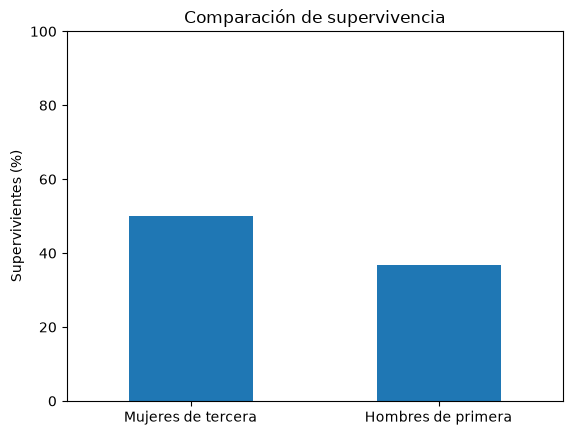

In [16]:
mujeres_tercera = df[(df["sex"] == "female") & (df["pclass"] == 3)]
hombres_primera = df[(df["sex"] == "male") & (df["pclass"] == 1)]

comparacion = pd.DataFrame({
    "pasajeros": [len(mujeres_tercera), len(hombres_primera)],
    "supervivencia (%)": [mujeres_tercera["survived"].mean() * 100,
                          hombres_primera["survived"].mean() * 100]
}, index=["Mujeres de tercera", "Hombres de primera"])

display(comparacion.round(2))
comparacion["supervivencia (%)"].plot.bar(rot=0)
plt.title("Comparación de supervivencia")
plt.ylabel("Supervivientes (%)")
plt.ylim(0, 100)
plt.show()

Sobrevivió el 50% de las mujeres de tercera clase y el 36.89% de los hombres de primera. En esta comparación, viajar en primera no te aseguraba sobrevivir.

# 3. Limpieza

- ¿Qué columnas son redundantes? **R=** pclass y class, embarked y embark_town
- ¿Qué haces con `who` y `adult_male`? **R=** Las eliminamos porque estan echas con información de la edad y el sexo, que son columnas que conservamos
- ¿Qué columna provoca fuga de información? **R=** alived, porque nos da en texto lo mismo que survived y si la mantenemos practicamente le damos la respuesta al modelo.
- Sin nombre ni billete, ¿los duplicados son errores o personas distintas? **R=** No lo sabemos con seguridad ya que dos pasajeros pueden comapartir las mismas caracteristicas pero realmente ser dos personas diferentes.
- ¿Qué decides para los faltantes de `deck`, `age` y `embarked`?

In [17]:
columnas_eliminadas = ["alive", "class", "embark_town", "who", "adult_male", "deck", "alone"]
df = df_original.drop(columns=columnas_eliminadas).copy()

print("Columnas eliminadas:", columnas_eliminadas)
print("Filas conservadas:", len(df))
print("Duplicados eliminados:", 0)

Columnas eliminadas: ['alive', 'class', 'embark_town', 'who', 'adult_male', 'deck', 'alone']
Filas conservadas: 891
Duplicados eliminados: 0


### Outliers: revisa `fare`, `age`, `sibsp` y `parch` con IQR y Z-score. ¿Error o valor raro pero real?

In [18]:
resultados = []

for col in ["fare", "age", "sibsp", "parch"]:
    valores = df_original[col].dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    z = (valores - valores.mean()) / valores.std()

    resultados.append({
        "columna": col,
        "límite inferior IQR": inferior,
        "límite superior IQR": superior,
        "IQR": ((valores < inferior) | (valores > superior)).sum(),
        "Z-score": (z.abs() > 3).sum()
    })

tabla_outliers = pd.DataFrame(resultados).set_index("columna")
tabla_outliers.round(2)

,límite inferior IQR,límite superior IQR,IQR,Z-score
columna,,,,
fare,-26.72,65.63,116,20
age,-6.69,64.81,11,2
sibsp,-1.50,2.50,46,30
parch,0.00,0.00,213,15


### Billetes de 0 £ y más de 500 £, edades menores de un año y ocho hermanos a bordo: ¿los eliminarías?

In [19]:
casos_raros = pd.Series({
    "Tarifa igual a 0": (df_original["fare"] == 0).sum(),
    "Tarifa mayor a 500": (df_original["fare"] > 500).sum(),
    "Edad menor a 1": (df_original["age"] < 1).sum(),
    "Ocho hermanos o cónyuges": (df_original["sibsp"] == 8).sum(),
    "Edades negativas": (df_original["age"] < 0).sum(),
    "Tarifas negativas": (df_original["fare"] < 0).sum()
})
casos_raros

Tarifa igual a 0            15
Tarifa mayor a 500           3
Edad menor a 1               7
Ocho hermanos o cónyuges     7
Edades negativas             0
Tarifas negativas            0
dtype: int64

### Split 80/20 estratificado antes de imputar: ¿se conserva el porcentaje de supervivientes?

In [20]:
X = df.drop(columns="survived")
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train = X_train.copy()
X_test = X_test.copy()

display(pd.DataFrame({
    "filas": [len(y), len(y_train), len(y_test)],
    "supervivencia (%)": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100]
}, index=["Total", "Train", "Test"]).round(2))

,filas,supervivencia (%)
Total,891,38.38
Train,712,38.34
Test,179,38.55


### Imputación de `age` y `embarked`: ¿de qué conjunto salen la mediana y la moda?

In [21]:
mediana_edad = X_train["age"].median()
moda_puerto = X_train["embarked"].mode()[0]

for datos in [X_train, X_test]:
    datos["age_missing"] = datos["age"].isna().astype(int)
    datos["age"] = datos["age"].fillna(mediana_edad)
    datos["embarked"] = datos["embarked"].fillna(moda_puerto)

print("Mediana de edad de train:", mediana_edad)
print("Moda del puerto de train:", moda_puerto)
print("Nulos en train:", X_train.isna().sum().sum())
print("Nulos en test:", X_test.isna().sum().sum())

Mediana de edad de train: 28.5
Moda del puerto de train: S
Nulos en train: 0
Nulos en test: 0


### Antes y después: compara filas, faltantes, distribuciones y supervivencia

,antes,después
filas,891.00,891.00
columnas,15.00,9.00
nulos,869.00,0.00
supervivencia (%),38.38,38.38


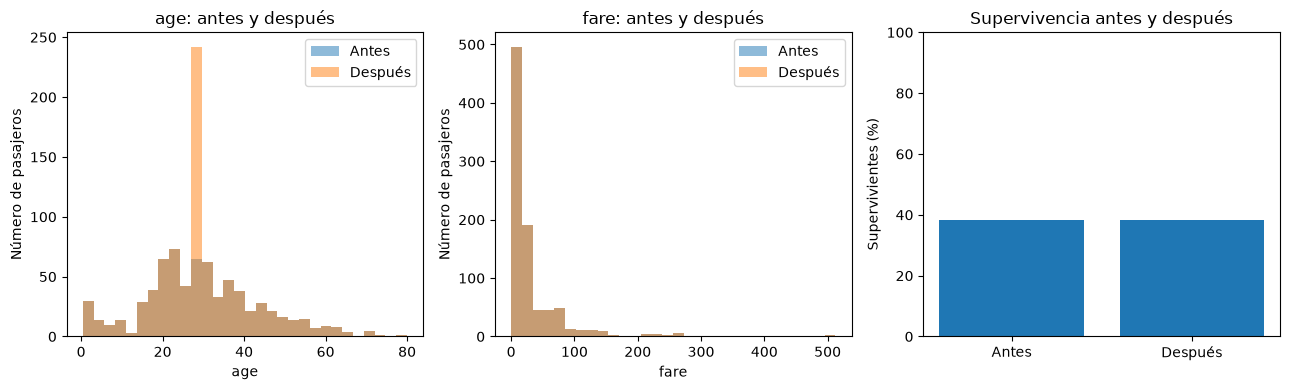

In [22]:
df_limpio = pd.concat([X_train, X_test]).sort_index()
df_limpio["survived"] = y

display(pd.DataFrame({
    "antes": [len(df_original), df_original.shape[1], df_original.isna().sum().sum(),
              df_original["survived"].mean() * 100],
    "después": [len(df_limpio), df_limpio.shape[1], df_limpio.isna().sum().sum(),
                df_limpio["survived"].mean() * 100]
}, index=["filas", "columnas", "nulos", "supervivencia (%)"]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes[:2], ["age", "fare"]):
    ax.hist(df_original[col].dropna(), bins=30, alpha=0.5, label="Antes")
    ax.hist(df_limpio[col], bins=30, alpha=0.5, label="Después")
    ax.set_title(f"{col}: antes y después")
    ax.set_xlabel(col)
    ax.set_ylabel("Número de pasajeros")
    ax.legend()

axes[2].bar(["Antes", "Después"], [df_original["survived"].mean() * 100,
                                  df_limpio["survived"].mean() * 100])
axes[2].set_title("Supervivencia antes y después")
axes[2].set_ylabel("Supervivientes (%)")
axes[2].set_ylim(0, 100)
plt.tight_layout()
plt.show()

# 4. Transformación y escalado

- Crea al menos dos variables y valida cada una contra `survived`.
- ¿Qué variable necesita logaritmo? ¿Qué haces con los ceros?
- ¿Qué variables son nominales y cuáles ordinales?
- ¿`pclass` como número o como one-hot? ¿Cuándo usar `drop="first"`?
- ¿StandardScaler o MinMaxScaler?
- ¿En qué orden van split, imputación y escalado?
- ¿Qué pasa si calculas la mediana de `age` incluyendo test?

### Variables nuevas: tamaño de familia y tramos de edad

,count,mean
family_size,,
1,434,29.95
2,129,55.04
3,77,62.34
4,22,72.73
5,14,21.43
6,16,6.25
7,11,36.36
8,4,0.00
11,5,0.00


,count,mean
age_group,,
infancia,55,60.00
adolescencia,30,46.67
adultez,609,36.62
mayor,18,16.67


,count,mean
age_missing,,
0,575,0.405
1,137,0.292


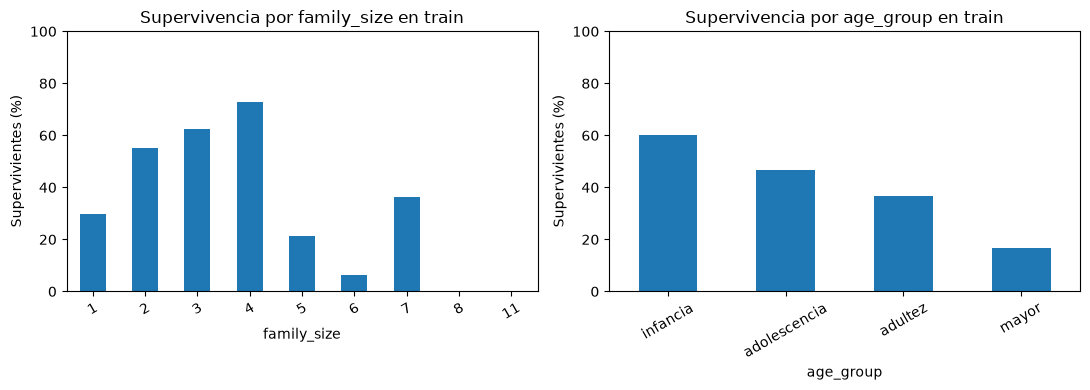

In [23]:
for datos in [X_train, X_test]:
    datos["family_size"] = datos["sibsp"] + datos["parch"] + 1
    datos["age_group"] = pd.cut(datos["age"], bins=[0, 12, 17, 59, np.inf],
                                labels=["infancia", "adolescencia", "adultez", "mayor"],
                                include_lowest=True)

validacion = X_train.copy()
validacion["survived"] = y_train

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["family_size", "age_group"]):
    resumen = validacion.groupby(col, observed=True)["survived"].agg(["count", "mean"])
    resumen["mean"] = resumen["mean"] * 100
    display(resumen.round(2))
    resumen["mean"].plot.bar(ax=ax, rot=30)
    ax.set_title(f"Supervivencia por {col} en train")
    ax.set_ylabel("Supervivientes (%)")
    ax.set_ylim(0, 100)

display(validacion.groupby("age_missing")["survived"].agg(["count", "mean"]).round(3))
plt.tight_layout()
plt.show()

### Asimetría de `fare`: comparación con `log1p`

Asimetría original: 4.65
Asimetría con log1p: 0.31


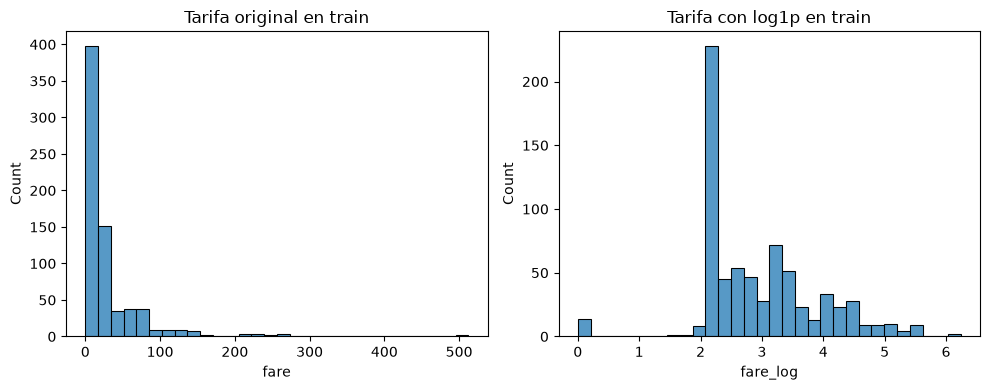

In [24]:
for datos in [X_train, X_test]:
    datos["fare_log"] = np.log1p(datos["fare"])

print("Asimetría original:", round(X_train["fare"].skew(), 2))
print("Asimetría con log1p:", round(X_train["fare_log"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(data=X_train, x="fare", bins=30, ax=axes[0])
axes[0].set_title("Tarifa original en train")
sns.histplot(data=X_train, x="fare_log", bins=30, ax=axes[1])
axes[1].set_title("Tarifa con log1p en train")
plt.tight_layout()
plt.show()

X_train = X_train.drop(columns="fare")
X_test = X_test.drop(columns="fare")

### Codificación ordinal: `pclass` y `age_group`

In [25]:
orden_edad = {"infancia": 0, "adolescencia": 1, "adultez": 2, "mayor": 3}

X_train["age_group"] = X_train["age_group"].map(orden_edad).astype(int)
X_test["age_group"] = X_test["age_group"].map(orden_edad).astype(int)

X_train[["pclass", "age_group"]].head()

,pclass,age_group
692,3,2
481,2,2
527,1,2
855,3,2
801,2,2


### Codificación one-hot: `sex` y `embarked`

In [26]:
nominales = ["sex", "embarked"]
codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_categoricas = codificador.fit_transform(X_train[nominales])
test_categoricas = codificador.transform(X_test[nominales])
columnas = codificador.get_feature_names_out(nominales)

train_categoricas = pd.DataFrame(train_categoricas, columns=columnas, index=X_train.index)
test_categoricas = pd.DataFrame(test_categoricas, columns=columnas, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=nominales), train_categoricas], axis=1)
X_test = pd.concat([X_test.drop(columns=nominales), test_categoricas], axis=1)

X_train.head()

,pclass,age,sibsp,parch,age_missing,family_size,age_group,fare_log,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
692,3,28.5,0,0,1,1,2,4.051712,0.0,1.0,0.0,0.0,1.0
481,2,28.5,0,0,1,1,2,0.000000,0.0,1.0,0.0,0.0,1.0
527,1,28.5,0,0,1,1,2,5.406181,0.0,1.0,0.0,0.0,1.0
855,3,18.0,0,1,0,2,2,2.336987,1.0,0.0,0.0,0.0,1.0
801,2,31.0,1,1,0,3,2,3.305054,1.0,0.0,0.0,0.0,1.0


### Escalado: aprende con train y aplica a train y test

In [27]:
numericas = ["age", "sibsp", "parch", "family_size", "fare_log"]
escalador = StandardScaler()

X_train[numericas] = escalador.fit_transform(X_train[numericas])
X_test[numericas] = escalador.transform(X_test[numericas])

display(pd.DataFrame({
    "media de train": X_train[numericas].mean(),
    "desviación de train": X_train[numericas].std(ddof=0),
    "media de test": X_test[numericas].mean()
}).round(3))

,media de train,desviación de train,media de test
age,0.0,1.0,-0.036
sibsp,-0.0,1.0,0.141
parch,-0.0,1.0,-0.053
family_size,0.0,1.0,0.066
fare_log,0.0,1.0,0.058


### Verificación final: sin nulos, todo numérico, mismas columnas y sin fuga de información

In [28]:
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()
assert X_train.select_dtypes(exclude="number").empty
assert X_test.select_dtypes(exclude="number").empty
assert X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert "survived" not in X_train.columns
assert "alive" not in X_train.columns
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert df_original.equals(pd.read_csv(DATA_DIR / "titanic.csv"))

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Columnas finales:", X_train.columns.tolist())
print("Verificación correcta")

X_train: (712, 13)
X_test: (179, 13)
y_train: (712,)
y_test: (179,)
Columnas finales: ['pclass', 'age', 'sibsp', 'parch', 'age_missing', 'family_size', 'age_group', 'fare_log', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']
Verificación correcta


# 5. Bitácora y conclusiones

### Bitácora de decisiones

In [33]:
bitacora = pd.DataFrame([
    ["alive", "Fuga de información", "Conservar / eliminar", "Eliminar", "Pq le damos la respuesta al modelo", len(df_original)],
    ["class", "Repite pclass", "Conservar una de las dos", "Eliminar class", "pclass conserva el orden", len(df_original)],
    ["embark_town", "Repite embarked", "Conservar una de las dos", "Eliminar embark_town", "El código de puerto basta", len(df_original)],
    ["who", "Derivada de edad y sexo", "Conservar / eliminar", "Eliminar", "Evitar información repetida", len(df_original)],
    ["adult_male", "Derivada de who", "Conservar / eliminar", "Eliminar", "Ya hay edad y sexo", len(df_original)],
    ["alone", "Derivada de sibsp y parch", "Conservar / eliminar", "Eliminar", "Se creará family_size", len(df_original)],
    ["deck", "Muchos faltantes", "Eliminar / categoría desconocida", "Eliminar", "Falta en más del 77 %", int(df_original["deck"].isna().sum())],
    ["Duplicados", "No hay identificador", "Eliminar / conservar", "Conservar", "Pueden ser personas distintas", int(df_original.duplicated(keep=False).sum())],
    ["age", "Edades faltantes", "Media / mediana / eliminar", "Mediana", "Menos sensible a extremos", int(df_original["age"].isna().sum())],
    ["embarked", "Puertos faltantes", "Moda / eliminar", "Moda", "Solo faltan dos valores", int(df_original["embarked"].isna().sum())],
    ["age_missing", "Distinguir edades imputadas", "Añadir / omitir", "Crear indicador", "No confundir imputado con observado", int(df_original["age"].isna().sum())],
    ["fare", "Outliers por IQR", "Eliminar / recortar / conservar", "Conservar y usar log1p", "No hay evidencia de error", int(tabla_outliers.loc["fare", "IQR"])],
    ["age", "Outliers por IQR", "Eliminar / conservar", "Conservar", "Bebés y mayores son plausibles", int(tabla_outliers.loc["age", "IQR"])],
    ["sibsp", "Outliers por IQR", "Eliminar / conservar", "Conservar", "Familias grandes son posibles", int(tabla_outliers.loc["sibsp", "IQR"])],
    ["parch", "Outliers por IQR", "Eliminar / conservar", "Conservar", "Son conteos de familiares", int(tabla_outliers.loc["parch", "IQR"])],
    ["family_size", "Representar familia", "Usar conteos / combinarlos", "sibsp + parch + 1", "Incluye al pasajero", len(df_original)],
    ["age_group", "Representar etapas de edad", "Edad / tramos", "Crear cuatro tramos", "Comparar etapas de edad", len(df_original)],
    ["fare_log", "Tarifa asimétrica", "Original / log / recorte", "log1p y quitar fare", "Reduce la cola y admite ceros", len(df_original)],
    ["sex, embarked", "Categorías nominales", "Numerar / one-hot", "One-hot sin drop", "No inventar un orden", len(df_original)],
    ["pclass, age_group", "Categorías con orden", "Ordinal / one-hot", "Conservar pclass y mapear edad", "Mantener un orden explícito", len(df_original)],
    ["Split", "Reservar test", "Aleatorio / estratificado", "80/20, estratificado, semilla 42", "Conservar proporción del objetivo", len(df_original)],
    ["Escalado", "Escalas diferentes", "StandardScaler / MinMaxScaler", "StandardScaler con train", "Comparar escalas tras log1p", len(df_original)]
], columns=["Columna", "Problema", "Opciones", "Decisión", "Por qué", "Afectados"])

bitacora.index = range(1, len(bitacora) + 1)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(bitacora)

,Columna,Problema,Opciones,Decisión,Por qué,Afectados
1,alive,Fuga de información,Conservar / eliminar,Eliminar,Pq le damos la respuesta al modelo,891
2,class,Repite pclass,Conservar una de las dos,Eliminar class,pclass conserva el orden,891
3,embark_town,Repite embarked,Conservar una de las dos,Eliminar embark_town,El código de puerto basta,891
4,who,Derivada de edad y sexo,Conservar / eliminar,Eliminar,Evitar información repetida,891
5,adult_male,Derivada de who,Conservar / eliminar,Eliminar,Ya hay edad y sexo,891
6,alone,Derivada de sibsp y parch,Conservar / eliminar,Eliminar,Se creará family_size,891
7,deck,Muchos faltantes,Eliminar / categoría desconocida,Eliminar,Falta en más del 77 %,688
8,Duplicados,No hay identificador,Eliminar / conservar,Conservar,Pueden ser personas distintas,160
9,age,Edades faltantes,Media / mediana / eliminar,Mediana,Menos sensible a extremos,177
10,embarked,Puertos faltantes,Moda / eliminar,Moda,Solo faltan dos valores,2


### Preguntas de conclusión

- ¿Cuáles son los tres factores más asociados con la supervivencia en este análisis?
- ¿Cuál fue la decisión más difícil y qué pasaría con otra opción?
- ¿Qué dato faltó para tomar mejores decisiones?
- ¿Cuál es la forma final de los cuatro conjuntos y qué columnas verá el modelo?

In [30]:
display(pd.DataFrame({
    "conjunto": ["X_train", "X_test", "y_train", "y_test"],
    "forma": [X_train.shape, X_test.shape, y_train.shape, y_test.shape]
}))
display(pd.Series(X_train.columns, name="Columnas que verá el modelo"))

,conjunto,forma
0,X_train,"(712, 13)"
1,X_test,"(179, 13)"
2,y_train,"(712,)"
3,y_test,"(179,)"


0          pclass
1             age
2           sibsp
3           parch
4     age_missing
5     family_size
6       age_group
7        fare_log
8      sex_female
9        sex_male
10     embarked_C
11     embarked_Q
12     embarked_S
Name: Columnas que verá el modelo, dtype: str